# Clasificación Automática de Modulaciones (AMC)
## Preprocesamiento — LSTM sobre I/Q+A/φ reducidos por símbolo

Prueba exploratoria de preprocesamiento (carpeta `Modelos_preproc/`, hermana de `Modelos iniciales/`):
en vez de darle a la LSTM una muestra I/Q por timestep, se arman los 4 canales I/Q/Amplitud/Fase
(`common.data.to_iq_amplitude_phase`) y se reducen a `reduced_channels` por símbolo con una
`Conv1d(kernel_size=stride=samples_per_symbol)` **aprendida** antes de la recurrencia
(`common.models.SymbolReduceLSTM`). RadioML 2016.10a tiene oversampling fijo de 8 muestras por
símbolo, así que la secuencia que ve la LSTM baja de 128 a 16 pasos — mucho menos cómputo/latencia
en la recurrencia, con una cantidad de parámetros similar a `LSTMClassifier` (depende de
`hidden_size`, no de la longitud de secuencia).

La clase y la transformación de datos viven en `../Modelos iniciales/common/` (misma fuente de
verdad que usan los notebooks de `Modelos iniciales/`), para no duplicar código.

## 1. Imports y configuración

In [4]:
import sys
sys.path.insert(0, "../Modelos iniciales")

import pickle

import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from common.models import SymbolReduceLSTM
from common.data import load_radioml_digital, split_dataset, make_loader, augment_rotate_iq, to_iq_amplitude_phase
from common.train import train_model, evaluate_by_snr, overall_accuracy, compute_cm

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cpu":
    try:
        import torch_directml
        DEVICE = torch_directml.device()  # GPU AMD/Intel en Windows (venv con torch_directml, p. ej. amc_env_dml)
    except ImportError:
        pass  # venv sin torch_directml (amc_env normal) -> sigue en CPU como antes
# nn.LSTM (fused kernel) no corre en DirectML -> forzar CPU para este notebook
if "torch_directml" in str(type(DEVICE)):
    DEVICE = "cpu"

DATASET_FOLDER = "../Modelos iniciales/rfml"  # Modelos_preproc/ no es hermana de rfml/

BATCH_SIZE = 256
EPOCHS = 200          # tope; el early stopping (PATIENCE) corta antes
PATIENCE = 10
SEED = 42
LR = 1e-3             # misma receta común que el resto (ver Resultados/README.md)
SCHEDULER = True      # ReduceLROnPlateau sobre val_loss
AUGMENT = True        # rotación de constelación I/Q (x4 en train), igual que el resto

# Hiperparámetros de arquitectura — modificar acá para probar otra config.
# samples_per_symbol=8: oversampling fijo de RadioML 2016.10a (128 muestras -> 16 símbolos).
# reduced_channels=2: los 2 grados de libertad reales de I/Q/A/φ (no colapsar a 1).
MODEL_KWARGS = dict(samples_per_symbol=8, reduced_channels=2, hidden_size=64, num_layers=1,
                     fc_hidden=32, dropout=0.3, input_norm=True)

print(f"Usando dispositivo: {DEVICE}")

Usando dispositivo: cpu


## 2. Carga y preparación del dataset

In [5]:
X, y, snrs, le = load_radioml_digital(dataset_folder=DATASET_FOLDER, seed=SEED)
N_CLASSES = len(le.classes_)
print(f"Clases ({N_CLASSES}): {list(le.classes_)}")

(X_train, y_train, snr_train), (X_val, y_val, snr_val), (X_test, y_test, snr_test) = split_dataset(
    X, y, snrs, seed=SEED
)

if AUGMENT:
    # la rotación actúa sobre I/Q (2 canales) -> aplicar ANTES de armar I/Q/A/φ
    X_train, y_train, snr_train = augment_rotate_iq(X_train, y_train, snr_train)

# I/Q (2 canales) -> I/Q/Amplitud/Fase (4 canales), que es lo que espera SymbolReduceLSTM
X_train = to_iq_amplitude_phase(X_train)
X_val = to_iq_amplitude_phase(X_val)
X_test = to_iq_amplitude_phase(X_test)

print(f"Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")

train_loader = make_loader(X_train, y_train, batch_size=BATCH_SIZE, shuffle=True)
val_loader = make_loader(X_val, y_val, batch_size=BATCH_SIZE, shuffle=False)

Clases (8): ['8PSK', 'BPSK', 'CPFSK', 'GFSK', 'PAM4', 'QAM16', 'QAM64', 'QPSK']
Train: (384000, 4, 128) | Val: (32000, 4, 128) | Test: (32000, 4, 128)


## 3. Entrenamiento — SymbolReduceLSTM

In [6]:
print("=== SymbolReduceLSTM (I/Q+A/φ reducidos por símbolo) ===")
print(f"Configuración: {MODEL_KWARGS}")
model = SymbolReduceLSTM(n_classes=N_CLASSES, **MODEL_KWARGS)
print(f"Parámetros: {model.count_parameters():,}")

model, history = train_model(
    model, train_loader, val_loader,
    epochs=EPOCHS, patience=PATIENCE, device=DEVICE, lr=LR,
    use_lr_scheduler=SCHEDULER, scheduler_factor=0.8, scheduler_patience=10, scheduler_min_lr=1e-7,
)
history["model_kwargs"] = MODEL_KWARGS

torch.save(model.state_dict(), "lstm_simbolo.pt")
with open("history.pkl", "wb") as f:
    pickle.dump(history, f)

=== SymbolReduceLSTM (I/Q+A/φ reducidos por símbolo) ===
Configuración: {'samples_per_symbol': 8, 'reduced_channels': 2, 'hidden_size': 64, 'num_layers': 1, 'fc_hidden': 32, 'dropout': 0.3, 'input_norm': True}
Parámetros: 19,890
Época  10/200 | Train Loss: 1.0552 | Val Loss: 1.0404 | Val Acc: 0.5419 | Patience: 0/10
Época  20/200 | Train Loss: 0.9828 | Val Loss: 0.9762 | Val Acc: 0.5738 | Patience: 0/10
Época  30/200 | Train Loss: 0.9543 | Val Loss: 0.9578 | Val Acc: 0.5822 | Patience: 1/10
Época  40/200 | Train Loss: 0.9409 | Val Loss: 0.9513 | Val Acc: 0.5887 | Patience: 4/10
Época  50/200 | Train Loss: 0.9317 | Val Loss: 0.9460 | Val Acc: 0.5901 | Patience: 9/10
Época  60/200 | Train Loss: 0.9262 | Val Loss: 0.9437 | Val Acc: 0.5892 | Patience: 9/10
Época  61/200 | Train Loss: 0.9249 | Val Loss: 0.9425 | Val Acc: 0.5901 | Patience: 10/10
Early stopping en época 61. Mejor val_loss: 0.9411


## 4. Evaluación

In [7]:
acc = overall_accuracy(model, X_test, y_test, device=DEVICE)
snr_acc = evaluate_by_snr(model, X_test, y_test, snr_test, device=DEVICE)

print(f"Accuracy global — SymbolReduceLSTM: {acc:.4f}")
print(f"Parámetros: {model.count_parameters():,}")

Accuracy global — SymbolReduceLSTM: 0.5890
Parámetros: 19,890


## 5. Gráficos

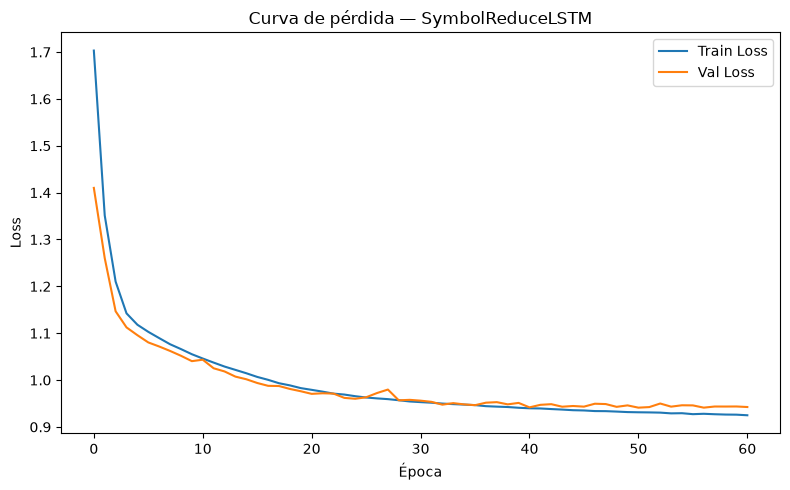

In [8]:
# Curva de pérdida
plt.figure(figsize=(8, 5))
plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["val_loss"], label="Val Loss")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.title("Curva de pérdida — SymbolReduceLSTM")
plt.legend()
plt.tight_layout()
plt.savefig("curva_perdida.png", dpi=150)
plt.show()

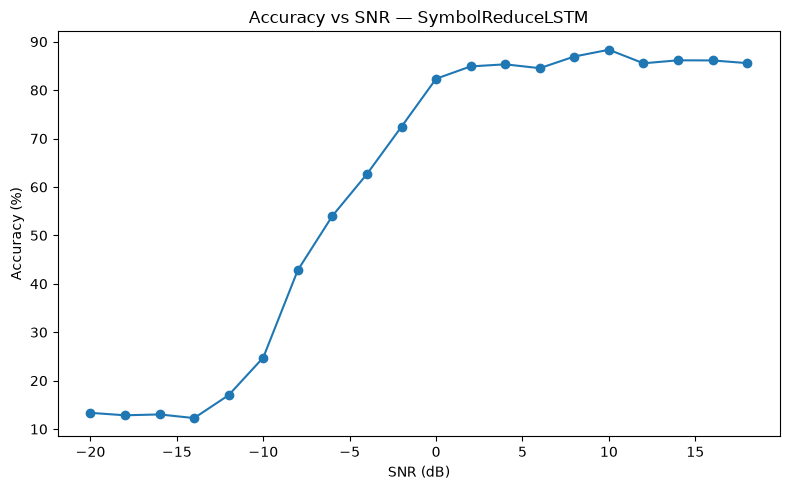

In [9]:
# Accuracy vs SNR
snr_levels = sorted(snr_acc.keys())
plt.figure(figsize=(8, 5))
plt.plot(snr_levels, [snr_acc[s] * 100 for s in snr_levels], marker="o")
plt.xlabel("SNR (dB)")
plt.ylabel("Accuracy (%)")
plt.title("Accuracy vs SNR — SymbolReduceLSTM")
plt.tight_layout()
plt.savefig("accuracy_vs_snr.png", dpi=150)
plt.show()

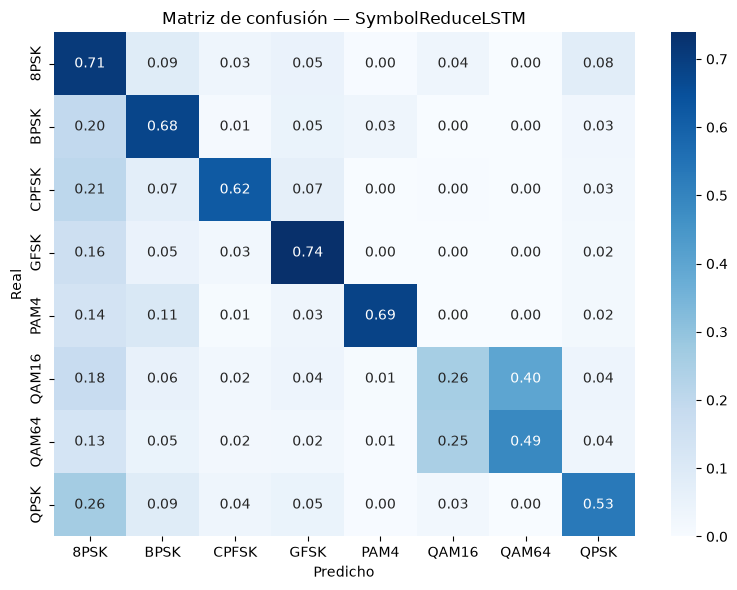

In [10]:
# Matriz de confusión (todos los SNR)
cm = compute_cm(model, X_test, y_test, device=DEVICE)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt=".2f", xticklabels=le.classes_, yticklabels=le.classes_,
            cmap="Blues", ax=ax)
ax.set_xlabel("Predicho")
ax.set_ylabel("Real")
ax.set_title("Matriz de confusión — SymbolReduceLSTM")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

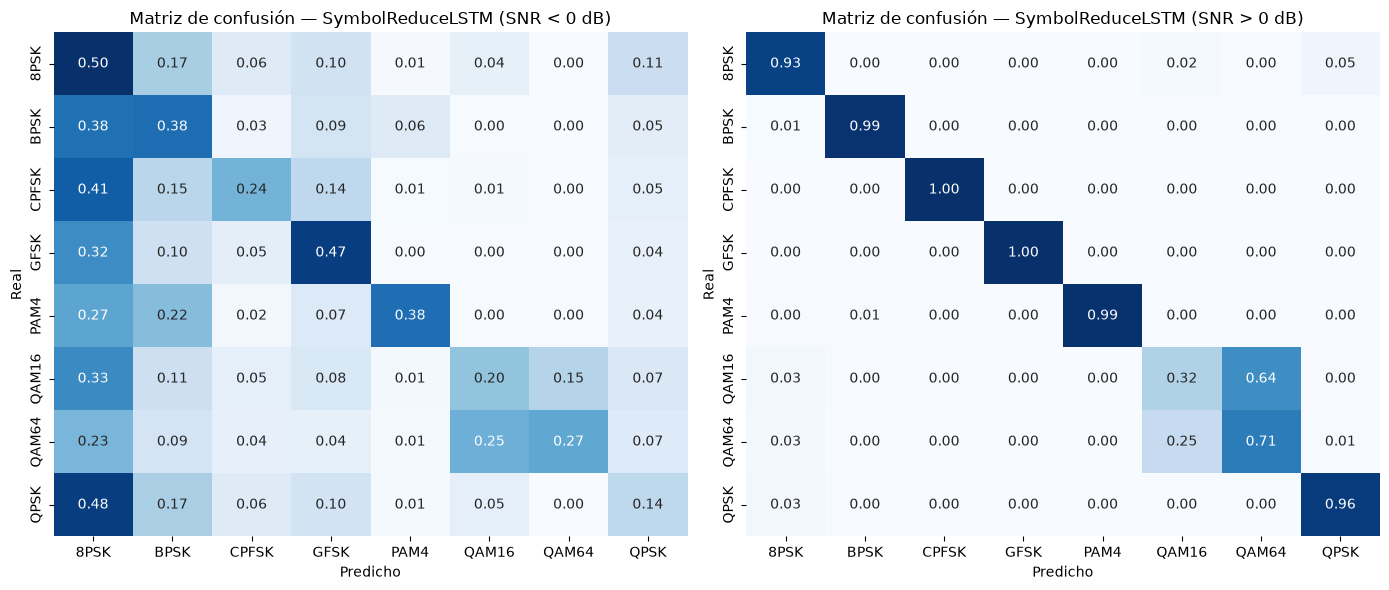

In [11]:
# Matrices de confusión por rango de SNR (bajo: <0 dB, alto: >0 dB)
mask_low = snr_test < 0
mask_high = snr_test > 0

cm_low = compute_cm(model, X_test[mask_low], y_test[mask_low], device=DEVICE)
cm_high = compute_cm(model, X_test[mask_high], y_test[mask_high], device=DEVICE)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, cm_snr, titulo in zip(axes, [cm_low, cm_high], ["SNR < 0 dB", "SNR > 0 dB"]):
    sns.heatmap(cm_snr, annot=True, fmt=".2f", xticklabels=le.classes_, yticklabels=le.classes_,
                cmap="Blues", ax=ax, cbar=False)
    ax.set_xlabel("Predicho")
    ax.set_ylabel("Real")
    ax.set_title(f"Matriz de confusión — SymbolReduceLSTM ({titulo})")
plt.tight_layout()
plt.savefig("confusion_matrix_por_snr.png", dpi=150)
plt.show()